# IMPORTING THE NECESSARY PACKAGES

In [52]:
import pandas as pd # Used for working with tables of data
import numpy as np # Used for numerical operations
import matplotlib.pyplot as plt # Used for creating basic charts
import seaborn as sns # used for statistical charts
 
from sklearn.linear_model import LinearRegression # used fto predict numeric outcomes
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor # for more accurate numeric predictions than a single line 
from sklearn.pipeline import Pipeline # Used for joining toether multpile steps so they run in sequence
from sklearn.preprocessing import StandardScaler # Used to rescale numeric columns so they're on a comparable scale (mean 0, standard deviation 1) )
from sklearn.model_selection import GridSearchCV, train_test_split # Used to split data into a "training" portion and a "test" portion
from sklearn.metrics import mean_squared_error, r2_score # Used to get the average size of the prediction errors and R2 for how much of the variation in the outcome the model explains

# IMPORTING THE DATASET

In [53]:
df = pd.read_csv(r"C:\Users\messi\dorca\OneDrive\Desktop\VEPHLA TASKS\PROJECTS\insurance.csv")

#Reading a csv insurance csv file from my laptop

df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [54]:
df.head() # Display only the first five rows

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [55]:
df.describe() # Displaying a little statistics for each column in the dataframe

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [56]:
df.info() # giving an overview or summary of the entire dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [57]:
# Converting an index object into a plain python list using only the column names with categorical datatype
newlist = df.select_dtypes(include='object').columns 
newlist = [item for item in newlist]
newlist

['sex', 'smoker', 'region']

# CREATING VISUALIZATIONS

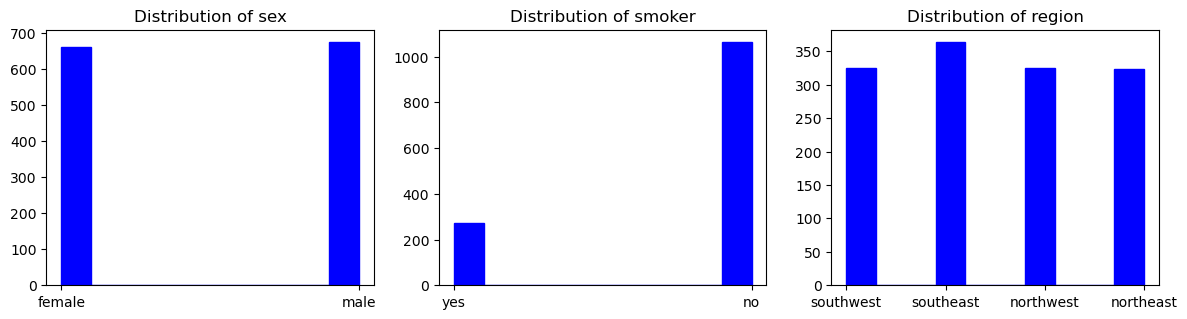

In [58]:
# Creating histogram grid for categorical columns
plt.figure(figsize = (12,6))
for g in range(3):
    plt.subplot(2,3, g+1)
    plt.hist(df[newlist[g]], color = 'blue', edgecolor = 'blue')
    plt.title(f'Distribution of {newlist[g]}')

plt.tight_layout() # adjusting spaces between the subplots
plt.show()

In [59]:
# Converting the index list into another plain python list using only the numeric columns
newlist2 = df.select_dtypes(exclude = 'object').columns
newlist2 = [item for item in newlist2]
newlist2

['age', 'bmi', 'children', 'charges']

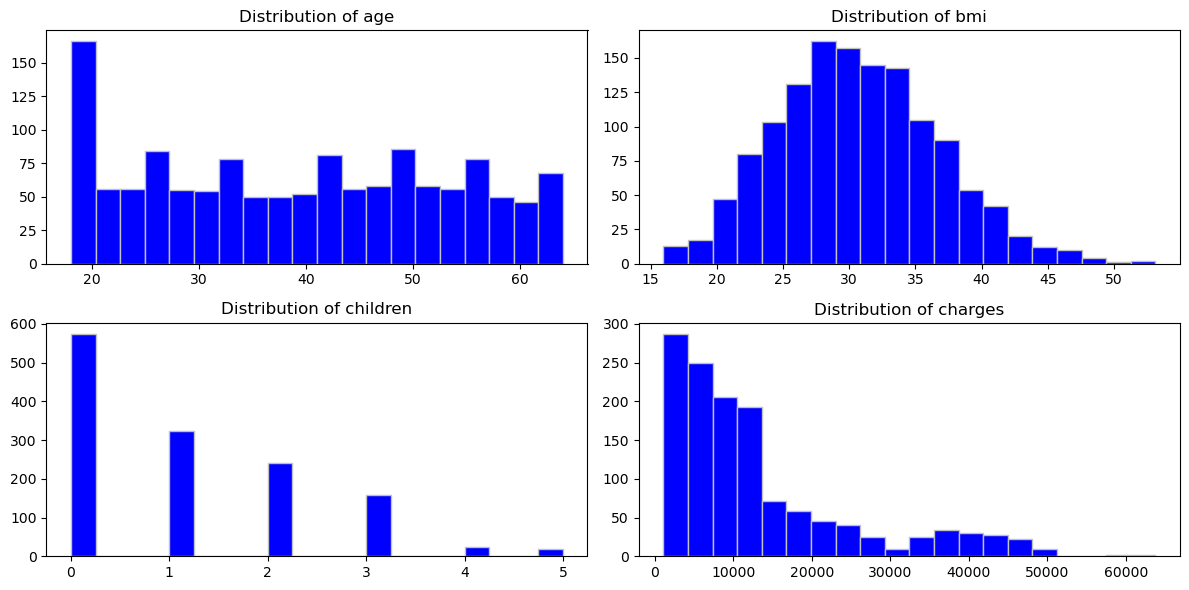

In [60]:
# Creating histogram grid for numeric columns
plt.figure(figsize =(12,6))
for g in range(4):
    plt.subplot(2,2, g+1)
    plt.hist(df[newlist2[g]], bins = 20, color = 'blue', edgecolor = 'silver')
    plt.title(f'Distribution of {newlist2[g]}')

plt.tight_layout()
plt.show()

In [61]:
df[newlist].describe() # Summarizinf rhe categorical columns

,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


# ENCODING OHE AND LABEL ENCODING

In [62]:
df.head() # Displaying the first five rows 

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [63]:
# Printing column names
for item in newlist:
    print(item)

sex
smoker
region


In [64]:
df2 = df # Creating a second dataframe

In [65]:
df2

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [66]:
# Creating two new columns through binary coding of two categorical columns from existing columns
df2['sex_e'] = df2['sex'].map({'female': 0, 'male': 1})
df2['smoker_e'] = df2['smoker'].map({'no': 0, 'yes': 1})

In [67]:
# Creating one-hot encoding for region
region_dummies = pd.get_dummies(df2['region'], prefix = 'region', drop_first=True)
df3 = pd.concat([df2, region_dummies], axis=1)

In [68]:
df3

,age,sex,bmi,children,smoker,region,charges,sex_e,smoker_e,region_northwest,region_southeast,region_southwest
0,19,female,27.900,0,yes,southwest,16884.92400,0,1,False,False,True
1,18,male,33.770,1,no,southeast,1725.55230,1,0,False,True,False
2,28,male,33.000,3,no,southeast,4449.46200,1,0,False,True,False
3,33,male,22.705,0,no,northwest,21984.47061,1,0,True,False,False
4,32,male,28.880,0,no,northwest,3866.85520,1,0,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830,1,0,True,False,False
1334,18,female,31.920,0,no,northeast,2205.98080,0,0,False,False,False
1335,18,female,36.850,0,no,southeast,1629.83350,0,0,False,True,False
1336,21,female,25.800,0,no,southwest,2007.94500,0,0,False,False,True


In [69]:
# Removing the original text columns 
df3=df3.drop(['sex', 'smoker', 'region'], axis = 1)

In [70]:
df3

,age,bmi,children,charges,sex_e,smoker_e,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,False,False,True
1,18,33.770,1,1725.55230,1,0,False,True,False
2,28,33.000,3,4449.46200,1,0,False,True,False
3,33,22.705,0,21984.47061,1,0,True,False,False
4,32,28.880,0,3866.85520,1,0,True,False,False
...,...,...,...,...,...,...,...,...,...
1333,50,30.970,3,10600.54830,1,0,True,False,False
1334,18,31.920,0,2205.98080,0,0,False,False,False
1335,18,36.850,0,1629.83350,0,0,False,True,False
1336,21,25.800,0,2007.94500,0,0,False,False,True


# CREATING CORRELATION HEATMAP

<Axes: >

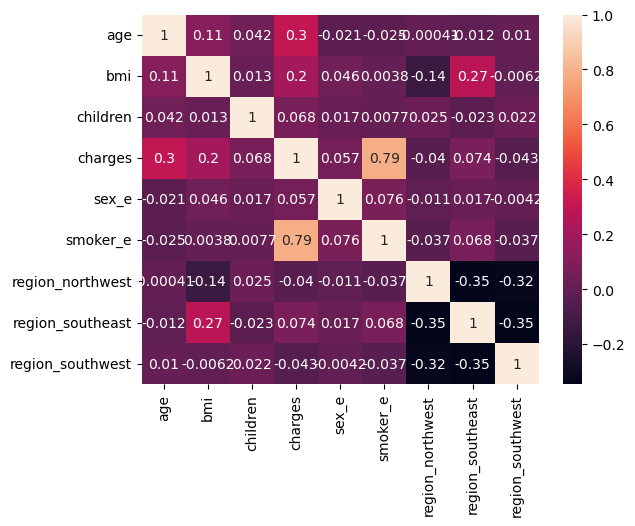

In [71]:
# Creating correlation heatmap

corr = df3.corr()
sns.heatmap(corr, annot=True)

<Axes: xlabel='smoker', ylabel='charges'>

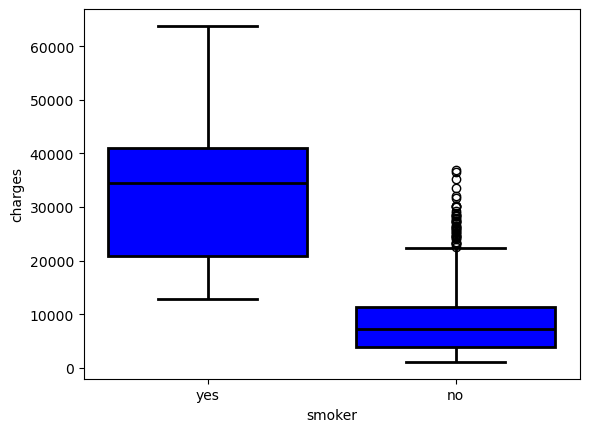

In [72]:
# Creating boxplot with title charges by smoking status
sns.boxplot(x='smoker', y='charges', color='blue', saturation= 20, linecolor='black', linewidth= 2, data=df)

<Axes: xlabel='bmi', ylabel='charges'>

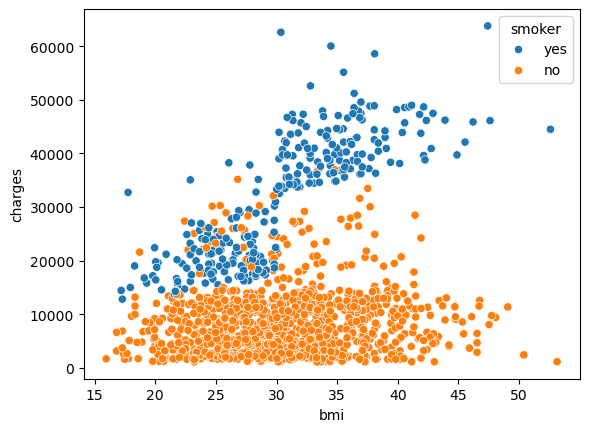

In [73]:
# Creating scatter plot - bmi vs charges, split bysmoker
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df)

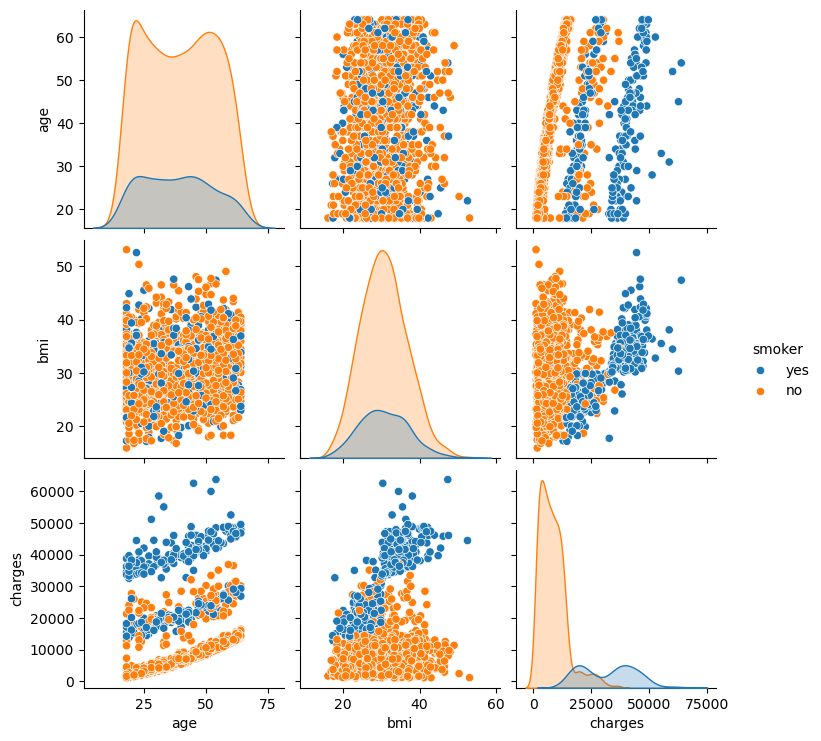

In [74]:
# Showing pair-wise relationship between age, bmi and charges by smoking status 
sns.pairplot(df[['age', 'bmi', 'charges', 'smoker']], hue='smoker')

In [75]:
df4 = df3

In [76]:
df4.head()

,age,bmi,children,charges,sex_e,smoker_e,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,False,False,True
1,18,33.770,1,1725.55230,1,0,False,True,False
2,28,33.000,3,4449.46200,1,0,False,True,False
3,33,22.705,0,21984.47061,1,0,True,False,False
4,32,28.880,0,3866.85520,1,0,True,False,False


In [77]:
# Splitting features from target value: charges is the value being predicted so we remove it from the predictors
x = df4.drop('charges', axis = 1)
y = df4['charges']
x.shape, y.shape

((1338, 8), (1338,))

In [78]:
# It rescales every feature to mean 0 and standard deviation 1, so that age column doesn't dominate a dummy column
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
x_scaled.shape

(1338, 8)

# TRAIN TEST SPLIT

In [79]:
from sklearn.model_selection import train_test_split

In [80]:
# splitting the data into 80% training portion and 20% test portion, so that the model can be evaluated on data it never saw during training and randomstate = 42 fixes the randomness so the same split happens every time the cell is rerun
x_train, x_test, y_train, y_test = train_test_split(x_scaled, y, test_size = 0.2, random_state = 42)
x_train.shape, x_test.shape, y_train.shape, y_test.shape 

((1070, 8), (268, 8), (1070,), (268,))

In [81]:
# Training a linear Regression model on the training data, then scores it on the held-out test set. The output is th
# R2 which explains about 78.4% of the variation in charges
lr_model = LinearRegression()
lr_model.fit(x_train, y_train)
lr_model.score(x_test, y_test)

0.7835929767120722

# MODEL TRAINING AND SCORE COMPARISON

In [92]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Building four different regression algorithms 
# Then looping through each algorithms and trains it and predicts on the test set
# and calculate the typical prediction error in dollars

models = {
    "Linear": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
}

for name, model in models.items():
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    rmse = mean_squared_error(y_test, y_pred)
    print(f"{name} -> R²: {r2_score(y_test, y_pred):.3f}, RMSE: {rmse:.2f}")

Linear -> R²: 0.784, RMSE: 33596915.85
Ridge -> R²: 0.784, RMSE: 33604956.54
Lasso -> R²: 0.784, RMSE: 33597338.15
Random Forest -> R²: 0.873, RMSE: 19680221.58


# CHECKING THE MODEL

In [94]:
# Checking for overfitting: According to the scores below, it generalizes well i.e the train model and test model scores is close to each other.
print("Train R²:", lr_model.score(x_train, y_train))
print("Test R²:", lr_model.score(x_test, y_test))

Train R²: 0.7417255854683333
Test R²: 0.7835929767120722


In [96]:
# Runniong a cross-validation: If the five values are clustered around 0.78, then we can trust thenumber.
# Cross validation trains and tests across 5 different splits and averages the result
from sklearn.model_selection import cross_val_score
scores = cross_val_score(LinearRegression(), x_scaled, y, cv=5, scoring='r2')
print(scores, scores.mean())

[0.76148179 0.70649339 0.77806343 0.73269475 0.75557475] 0.7468616243473741


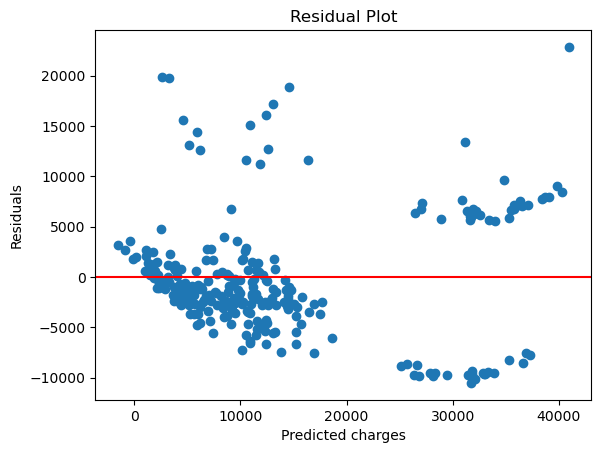

In [97]:
# Check residuals: Plotting residuals (actual - predicted) 
y_pred = lr_model.predict(x_test)
residuals = y_test - y_pred

plt.scatter(y_pred, residuals)
plt.axhline(0, color='red')
plt.xlabel('Predicted charges')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()